# Credit Risk

32k+ rows of data

[Dataset Source](https://www.kaggle.com/datasets/laotse/credit-risk-dataset/data)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from helper import *
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, FunctionTransformer

sns.set_style("darkgrid")
sns.set_theme(
    "notebook",
    rc={
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "figure.titlesize": 16,
        "figure.titleweight": "bold",
    },
)
sns.set_palette("rainbow")

## 1. Importing

In [2]:
df_import = pd.read_csv("data/credit_risk_dataset.csv")
df = df_import.copy()
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
df.shape

(32581, 12)

Styling choice improvements:
* removing "person_" prefix from variable names
* moving target variable `loan_status` to last column

In [4]:
df = df.rename(columns=lambda col: col.replace("person_", ""))

df = df.rename(columns={
    "home_ownership": "ownership_type",
    "emp_length": "employment_length",
    "loan_amnt": "loan_amt",
    "loan_percent_income": "loan_pct_income",
    "cb_default_on_file": "historical_default",
    "cb_cred_hist_length": "cred_history_length"
})

columns = [col for col in df.columns if col not in ["historical_default", "loan_status"]]
columns += ["historical_default", "loan_status"]
df = df[columns]

In [5]:
df.columns

Index(['age', 'income', 'ownership_type', 'employment_length', 'loan_intent',
       'loan_grade', 'loan_amt', 'loan_int_rate', 'loan_pct_income',
       'cred_history_length', 'historical_default', 'loan_status'],
      dtype='str')

In [6]:
df["historical_default"] = df["historical_default"].map({"N": 0, "Y": 1})

In [7]:
df["loan_intent"] = df["loan_intent"].str.lower()
df["ownership_type"] = df["ownership_type"].str.lower()

In [8]:
df.head()

,age,income,ownership_type,employment_length,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
0,22,59000,rent,123.0,personal,D,35000,16.02,0.59,3,1,1
1,21,9600,own,5.0,education,B,1000,11.14,0.10,2,0,0
2,25,9600,mortgage,1.0,medical,C,5500,12.87,0.57,3,0,1
3,23,65500,rent,4.0,medical,C,35000,15.23,0.53,2,0,1
4,24,54400,rent,8.0,medical,C,35000,14.27,0.55,4,1,1


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  32581 non-null  int64  
 1   income               32581 non-null  int64  
 2   ownership_type       32581 non-null  str    
 3   employment_length    31686 non-null  float64
 4   loan_intent          32581 non-null  str    
 5   loan_grade           32581 non-null  str    
 6   loan_amt             32581 non-null  int64  
 7   loan_int_rate        29465 non-null  float64
 8   loan_pct_income      32581 non-null  float64
 9   cred_history_length  32581 non-null  int64  
 10  historical_default   32581 non-null  int64  
 11  loan_status          32581 non-null  int64  
dtypes: float64(3), int64(6), str(3)
memory usage: 3.0 MB


Feature Name	Description
person_age	Age
person_income	Annual Income
person_home_ownership	Home ownership
person_emp_length	Employment length (in years)
loan_intent	Loan intent
loan_grade	Loan grade
loan_amnt	Loan amount
loan_int_rate	Interest rate
loan_status	Loan status (0 is non default 1 is default)
loan_percent_income	Percent income
cb_person_default_on_file	Historical default
cb_preson_cred_hist_length	Credit history length

## Data Audit & Cleaning

In [10]:
df.isna().sum()[df.isna().sum() > 0]

employment_length     895
loan_int_rate        3116
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(165)

⚠️ There are nulls & duplicates in the data

In [12]:
df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist())

,age,income,ownership_type,employment_length,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
15944,21,8088,rent,NaN,medical,C,1200,15.23,0.15,2,1,0
16835,21,8088,rent,NaN,medical,C,1200,15.23,0.15,2,1,0
2431,21,15600,rent,0.0,medical,A,2800,7.40,0.18,4,0,1
17758,21,15600,rent,0.0,medical,A,2800,7.40,0.18,4,0,1
2498,21,18000,rent,0.0,debtconsolidation,A,3000,7.90,0.17,2,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
32010,42,39996,mortgage,2.0,homeimprovement,A,2500,5.42,0.06,12,0,0
29484,43,11340,rent,4.0,education,C,1950,NaN,0.17,11,0,1
32279,43,11340,rent,4.0,education,C,1950,NaN,0.17,11,0,1
31676,49,120000,mortgage,12.0,medical,B,12000,10.99,0.10,12,0,0


Duplicates seem sensible, and not a product of data integrity or encoding issues.

In [13]:
cat_cols = ["ownership_type", "loan_intent", "loan_grade"]

target_col = ["loan_status"]

num_cols = df.select_dtypes(include="number").columns.drop(target_col, errors="ignore").tolist()

Categorical Columns 

In [14]:
for col in cat_cols:
    print(f"{df[col].value_counts()}\n")

ownership_type
rent        16446
mortgage    13444
own          2584
other         107
Name: count, dtype: int64

loan_intent
education            6453
medical              6071
venture              5719
personal             5521
debtconsolidation    5212
homeimprovement      3605
Name: count, dtype: int64

loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64



In [15]:
df["loan_intent"] = df["loan_intent"].replace({
    "debtconsolidation": "debt consolidation",
    "homeimprovement": "home improvement"
})

✅ No data integrity issues seem to be in our 3 categorical string columns. No spelling or input errors except missing spaces for readability

#### Numerical Columns

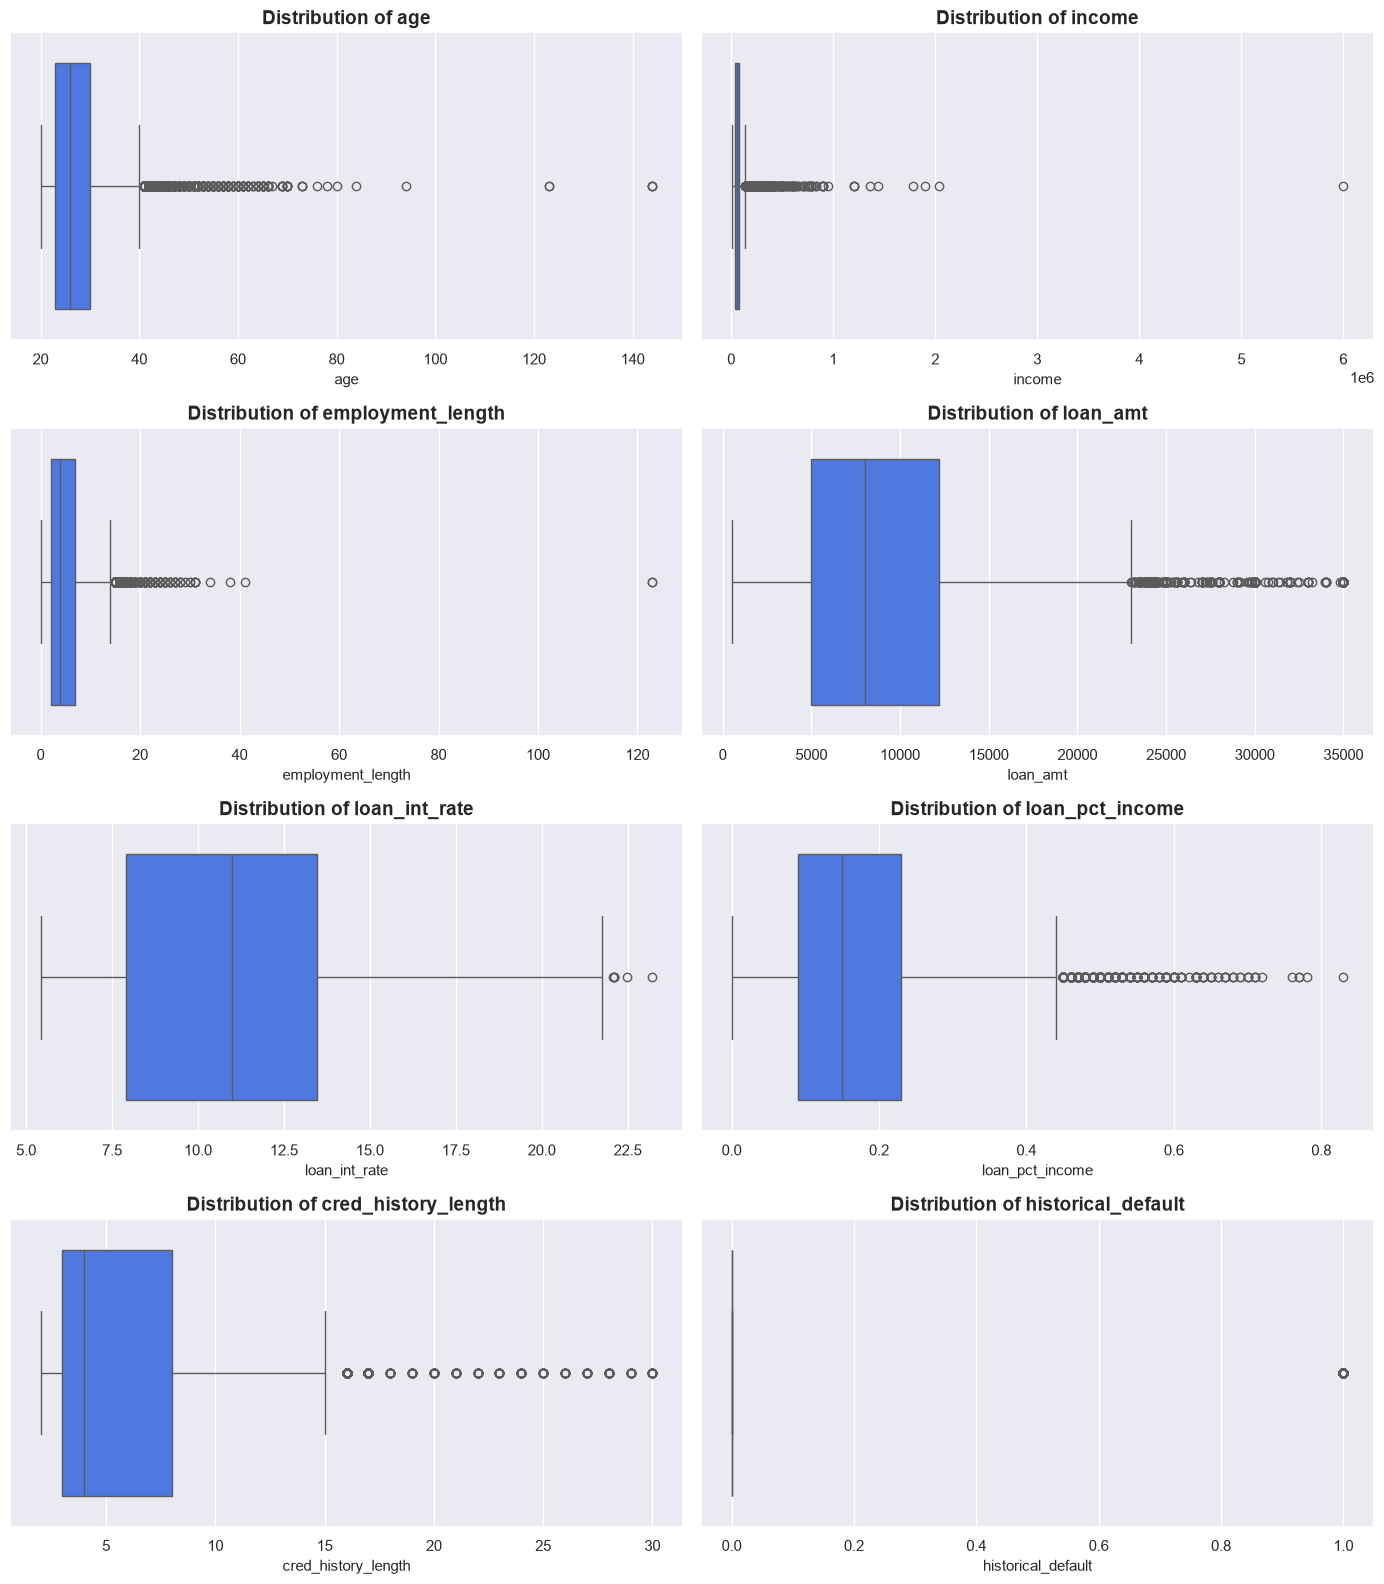

In [16]:
fig, axes = plt.subplots(
    nrows=math.ceil(len(num_cols) / 2),
    ncols=2,
    figsize=(14, 4 * math.ceil(len(num_cols) / 2))
)

axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

✅ No negative values
✅ Adult ages

In [17]:
df.nlargest(10, "age")

,age,income,ownership_type,employment_length,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
81,144,250000,rent,4.0,venture,C,4800,13.57,0.02,3,0,0
183,144,200000,mortgage,4.0,education,B,6000,11.86,0.03,2,0,0
32297,144,6000000,mortgage,12.0,personal,C,5000,12.73,0.00,25,0,0
575,123,80004,rent,2.0,education,B,20400,10.25,0.25,3,0,0
747,123,78000,rent,7.0,venture,B,20000,NaN,0.26,4,0,0
32416,94,24000,rent,1.0,medical,C,6500,NaN,0.27,27,0,0
32506,84,94800,mortgage,2.0,personal,A,10000,7.51,0.11,24,0,0
32422,80,64000,rent,7.0,medical,B,6800,11.71,0.11,25,0,0
32355,78,48000,rent,41.0,medical,A,3000,7.51,0.06,25,0,0
32534,76,75000,rent,23.0,medical,A,15000,8.94,0.20,25,0,0


In [18]:
df.nlargest(5, "employment_length")

,age,income,ownership_type,employment_length,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
0,22,59000,rent,123.0,personal,D,35000,16.02,0.59,3,1,1
210,21,192000,mortgage,123.0,venture,A,20000,6.54,0.10,4,0,0
32355,78,48000,rent,41.0,medical,A,3000,7.51,0.06,25,0,0
32515,53,106000,mortgage,38.0,personal,B,20000,9.88,0.19,23,0,0
32428,58,49000,mortgage,34.0,medical,D,7500,13.55,0.15,24,1,1


In [19]:
df.nlargest(10, "cred_history_length")

,age,income,ownership_type,employment_length,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
32320,55,50000,rent,2.0,home improvement,A,20000,7.51,0.40,30,0,1
32326,64,105000,rent,8.0,home improvement,E,20000,18.64,0.19,30,0,0
32353,51,37200,rent,4.0,medical,B,3000,10.62,0.08,30,0,1
32357,53,34000,mortgage,0.0,medical,B,10000,10.39,0.29,30,0,1
32366,58,20000,rent,0.0,education,B,4000,9.99,0.20,30,0,0
32395,51,46560,mortgage,2.0,personal,A,11600,8.94,0.25,30,0,0
32403,60,49008,own,5.0,personal,C,12000,13.79,0.24,30,1,0
32421,57,53000,mortgage,1.0,personal,C,5800,13.16,0.11,30,1,0
32446,51,62046,rent,8.0,venture,A,8000,NaN,0.13,30,0,0
32448,52,83200,rent,0.0,debt consolidation,C,8000,15.96,0.10,30,1,0


In [20]:
df.nlargest(10, "income")

,age,income,ownership_type,employment_length,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
32297,144,6000000,mortgage,12.0,personal,C,5000,12.73,0.00,25,0,0
30049,42,2039784,rent,0.0,venture,C,8450,12.29,0.00,15,1,0
32546,60,1900000,mortgage,5.0,personal,A,1500,NaN,0.00,21,0,0
32497,63,1782000,rent,13.0,education,C,12025,14.27,0.01,30,0,0
31924,44,1440000,mortgage,7.0,debt consolidation,A,6400,7.40,0.00,15,0,0
31922,47,1362000,mortgage,9.0,venture,A,6600,7.74,0.00,17,0,0
17833,32,1200000,mortgage,1.0,venture,A,12000,7.51,0.01,8,0,0
29119,36,1200000,own,16.0,medical,A,10000,6.54,0.01,11,0,0
29120,40,1200000,mortgage,1.0,medical,A,10000,NaN,0.01,16,0,0
17834,34,948000,mortgage,18.0,personal,B,2000,9.99,0.00,7,0,0


No age < cred hist limit

In [21]:
df[
    (df["cred_history_length"] > df["age"])
].sort_values("age", ascending=False)

,age,income,ownership_type,employment_length,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status


In [22]:
df[df["employment_length"] > df["age"] - 15]

,age,income,ownership_type,employment_length,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
0,22,59000,rent,123.0,personal,D,35000,16.02,0.59,3,1,1
210,21,192000,mortgage,123.0,venture,A,20000,6.54,0.10,4,0,0


Based on these extreme outliers that suggest data errors, rules and data limits will be enforced:
* Age >= 100
* Employment_length > age - 15 
    * Where employment_length is over 

In [23]:
(df["age"] > 100).sum()

np.int64(5)

In [24]:
df = df.drop(
    df[
        (df["age"] > 100) |
        (df["employment_length"] > df["age"] - 15)
    ].index
)

## 📊 2. EDA

In [25]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,32574.0,27.718426,6.204987,20.00,23.00,26.00,30.00,94.00
income,32574.0,65878.480813,52531.938809,4000.00,38500.00,55000.00,79200.00,2039784.00
employment_length,31679.0,4.782064,4.034948,0.00,2.00,4.00,7.00,41.00
loan_amt,32574.0,9588.018051,6320.249598,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29459.0,11.011529,3.240497,5.42,7.90,10.99,13.47,23.22
loan_pct_income,32574.0,0.170202,0.106755,0.00,0.09,0.15,0.23,0.83
cred_history_length,32574.0,5.804108,4.053873,2.00,3.00,4.00,8.00,30.00
historical_default,32574.0,0.176337,0.381112,0.00,0.00,0.00,0.00,1.00
loan_status,32574.0,0.218180,0.413017,0.00,0.00,0.00,0.00,1.00


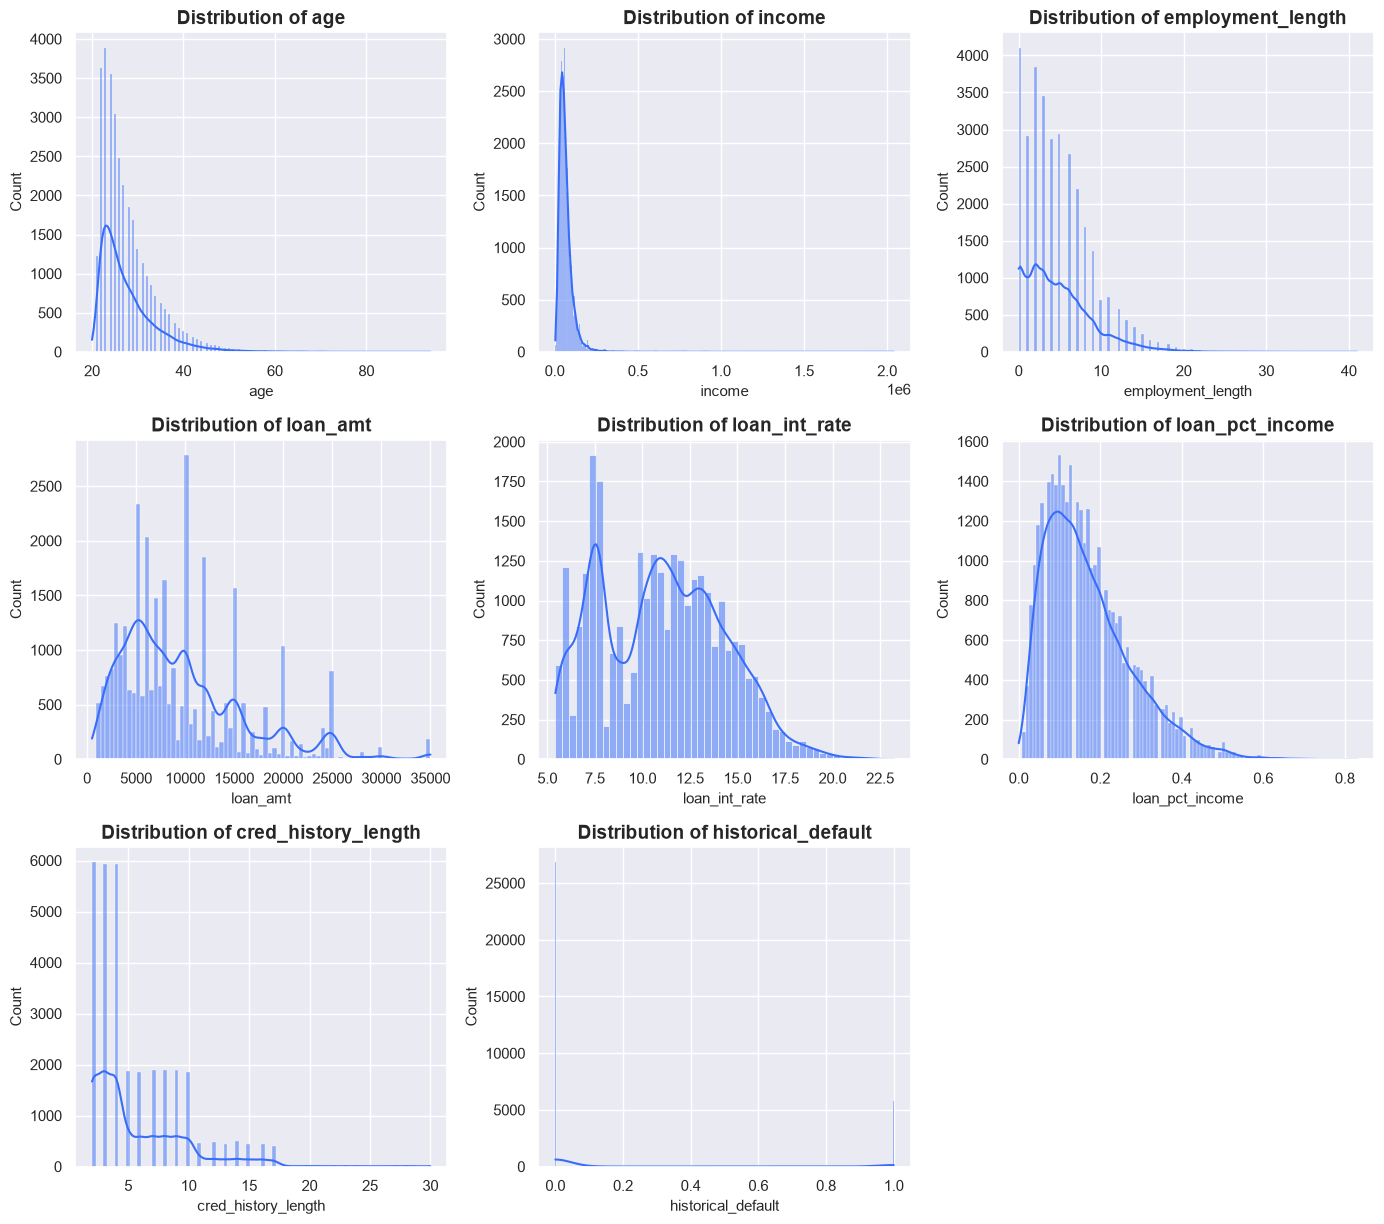

In [26]:
fig, axes = plt.subplots(
    nrows=math.ceil(len(num_cols) / 2),
    ncols=3,
    figsize=(14, 4 * math.ceil(len(num_cols) / 2))
)

axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True)
    axes[i].set_title(f"Distribution of {col}")

for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

All numerical variables are predominantly right-skewed

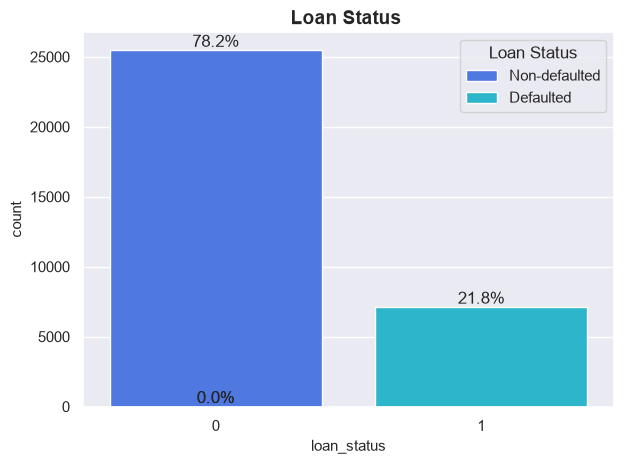

In [27]:
ax = sns.countplot(data=df, x="loan_status", hue="loan_status")

for bar in ax.patches:
    pct = bar.get_height() / len(df) * 100
    ax.annotate(f"{pct:.1f}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")

plt.title("Loan Status ")
ax.legend(title="Loan Status", labels=["Non-defaulted", "Defaulted"])
plt.tight_layout()
plt.show()

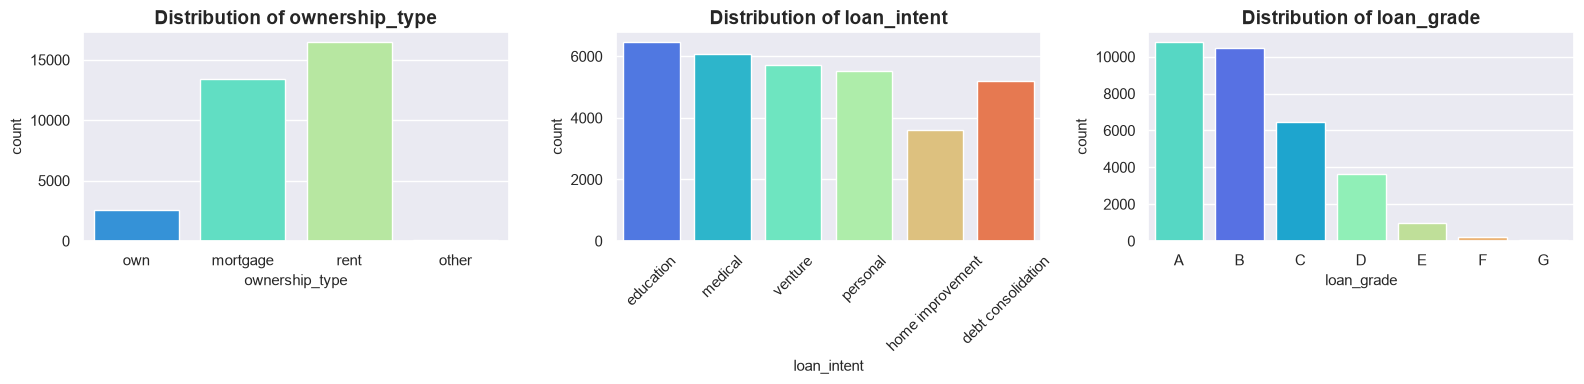

In [28]:
cat_cols = df.select_dtypes(include=["object", "str", "category"]).columns.tolist()

fig, axes = plt.subplots(
    nrows=math.ceil(len(cat_cols) / 3),
    ncols=3,
    figsize=(16, 4 * math.ceil(len(cat_cols) / 3))
)

axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = list("ABCDEFG") if col == "loan_grade" else None

    sns.countplot(
        data=df, x=col, ax=axes[i],
        order=order, palette="rainbow", hue=col, legend=False
    )
    axes[i].set_title(f"Distribution of {col}")

    if col == "loan_intent":
        axes[i].tick_params(axis="x", rotation=45)

for i in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

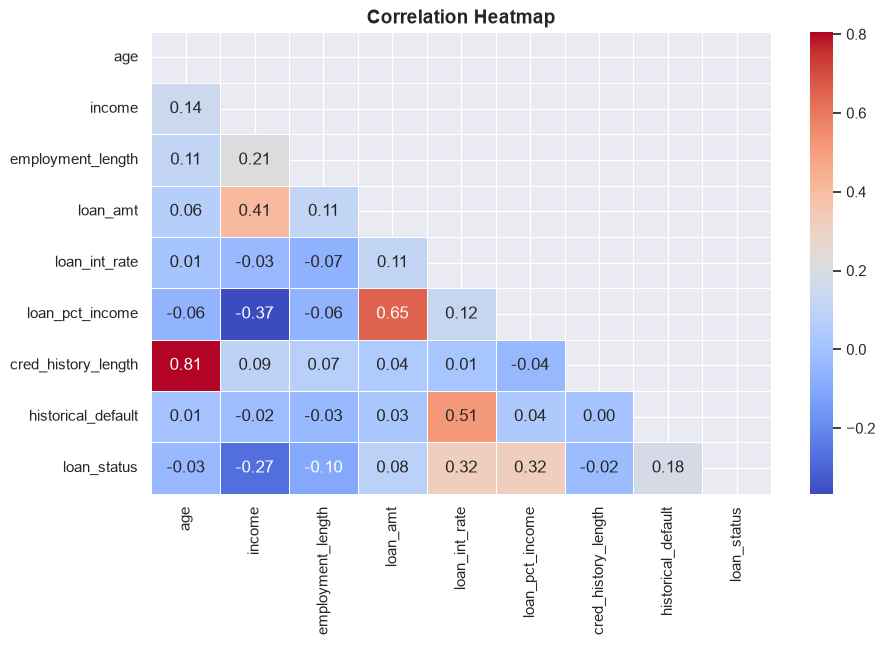

In [29]:
num_features = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))

corr = num_features.corr(method="spearman")
matrix = np.triu(corr)

sns.heatmap(corr, mask=matrix, cmap="coolwarm", annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

#### VIF / Multicollinearity check

If there are highly multicollinear variables, there is possibly a need for more preprocessing as these can distort model estimates (inflated sensitivity and high variance). Multicollinearity can be computed via Variance Inflation Factor:

## Modeling

In [30]:
X = df.drop(columns="loan_status")
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (26059, 11)
Test: (6515, 11)


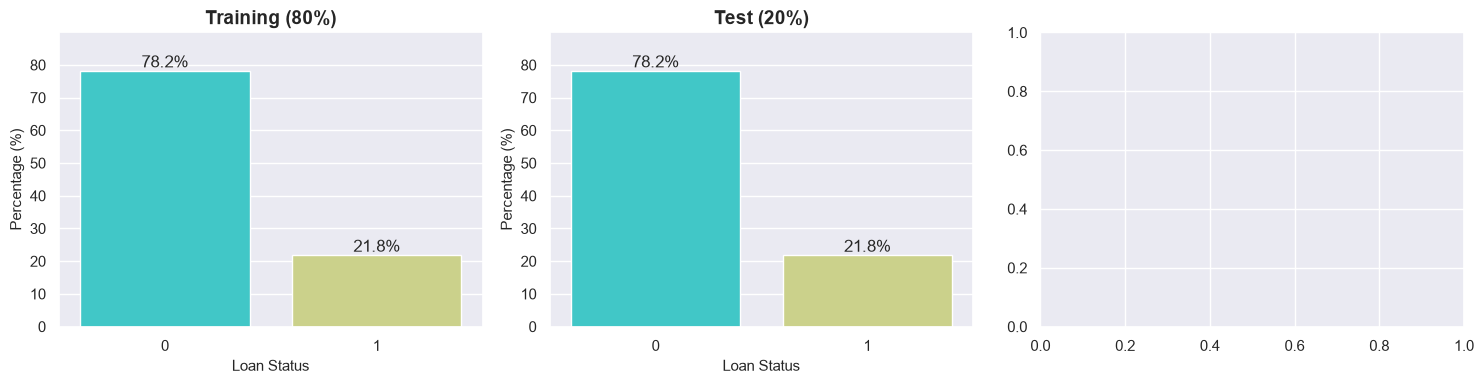

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, split, title in zip(
    axes,
    [y_train, y_test],
    ["Training (80%)","Test (20%)"]
):
    percentages = split.value_counts(normalize=True).sort_index() * 100

    sns.barplot(
        x=percentages.index,
        y=percentages.values,
        ax=ax,
        hue=percentages.index,
        palette="rainbow",
        legend=False
    )

    for bar in ax.patches:
        ax.annotate(
            f"{bar.get_height():.1f}%",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom"
        )

    ax.set_title(title)
    ax.set_xlabel("Loan Status")
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, percentages.max() * 1.15)

plt.tight_layout()
plt.show()

In [32]:
ohe_cols    = ["ownership_type", "loan_intent"]
ord_cols    = ["loan_grade"]
grade_order = [["A", "B", "C", "D", "E", "F", "G"]]

skewed_nums = ["income", "employment_length", "loan_amt",
               "loan_pct_income", "cred_history_length"]
other_nums  = ["age", "loan_int_rate", "loan_int_rate_missing",
               "historical_default"]

log1p = FunctionTransformer(np.log1p, feature_names_out="one-to-one")

column_prep = ColumnTransformer(
    transformers=[
        ("ohe", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False)),
        ]), ohe_cols),

        ("ord", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ord", OrdinalEncoder(categories=grade_order,
                                   handle_unknown="use_encoded_value",
                                   unknown_value=-1)),
        ]), ord_cols),

        ("skewed", Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("log", log1p),
        ]), skewed_nums),

        ("num", SimpleImputer(strategy="median"), other_nums),
    ],
    remainder="drop",
)
column_prep.set_output(transform="pandas")

preprocessor = Pipeline([
    ("rate_by_grade", GroupMedianImputer(target="loan_int_rate", group="loan_grade")),
    ("columns", column_prep),
])

X_train_p = preprocessor.fit_transform(X_train, y_train)
X_test_p  = preprocessor.transform(X_test)

print(X_train_p.shape, X_train_p.isna().sum().sum()) 

(26059, 21) 0


#### Baseline model

In [33]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_p, y_train)

results, new_results = score_predictions(
    dummy.predict_proba(X_train_p)[:, 1],
    dummy.predict_proba(X_test_p)[:, 1],
    y_train, y_test,
    model_name="Dummy (most_frequent)",
    params=dummy.get_params(),
)
new_results

,Model,Test PR-AUC,Test ROC-AUC,Train ROC-AUC,F1,Precision,Recall,Threshold,Params
0,Dummy (most_frequent),0.218,0.5,0.5,0.0,0.0,0.0,0.5,"{'constant': None, 'random_state': None, 'stra..."
